# Müşteri Kaybı (Churn) Tahmini — PCA ve Makine Öğrenmesi Modellerinin Karşılaştırılması

**Problem:** Bir telekom şirketinin 3.150 müşterisine ait 9 aylık kullanım verisiyle, sonraki 3 ay içinde hangi müşterilerin ayrılacağını tahmin etmek.

**Neden önemli?** Yeni müşteri kazanmak, mevcut müşteriyi tutmaktan genellikle çok daha pahalıdır. Ayrılma riski yüksek müşterileri önceden bulmak, elde tutma kampanyalarını doğru kişilere yönlendirmeyi sağlar. Aynı yaklaşım sigortacılıkta poliçe yenilememe, bankacılıkta hesap kapatma gibi problemlere doğrudan uygulanabilir.

**Yapılanlar:**
1. Keşifsel veri analizi ve çoklu bağlantı (VIF) incelemesi
2. PCA ile boyut indirgeme (%95 varyans)
3. Lojistik Regresyon, Karar Ağacı, Random Forest, SVM ve Gradient Boosting modellerinin ham veri ve PCA verisi üzerinde karşılaştırılması
4. Grid Search ile Randomized Search hiperparametre optimizasyonunun karşılaştırılması (Random Forest)
5. Aşırı öğrenme kontrolü, değişken önemi ve iş odaklı yorum (kazanç eğrisi)

**Veri:** [UCI Iranian Churn Dataset](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset) (CC BY 4.0)

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import randint, uniform, loguniform

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RANDOM_STATE = 42
DATA_PATH = Path("data/Customer Churn.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

def kaydet(fig, ad):
    fig.savefig(FIG_DIR / f"{ad}.png", dpi=150, bbox_inches="tight")

## 1. Veriyi yükleme ve hazırlama

In [2]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)

sutun_isimleri = {
    "Call Failure": "Arama Hatası",
    "Complains": "Şikayet",
    "Subscription Length": "Abonelik Süresi",
    "Charge Amount": "Ücret Seviyesi",
    "Seconds of Use": "Kullanım Süresi (sn)",
    "Frequency of use": "Kullanım Sıklığı",
    "Frequency of SMS": "SMS Sıklığı",
    "Distinct Called Numbers": "Farklı Aranan Numara",
    "Age Group": "Yaş Grubu",
    "Tariff Plan": "Tarife Planı",
    "Status": "Durum",
    "Age": "Yaş",
    "Customer Value": "Müşteri Değeri",
    "Churn": "Müşteri Kaybı",
}
df = df.rename(columns=sutun_isimleri)

# İkili değişkenleri 0/1 olarak kodla (orijinal kodlama 1/2)
df["Kontratlı Tarife"] = (df.pop("Tarife Planı") == 2).astype(int)   # 1: ön ödemeli, 2: kontratlı
df["Pasif Hesap"] = (df.pop("Durum") == 2).astype(int)              # 1: aktif, 2: pasif

HEDEF = "Müşteri Kaybı"
print(f"Boyut: {df.shape} | Eksik değer: {df.isna().sum().sum()}")
print(df[HEDEF].value_counts().rename({0: "Kalan (0)", 1: "Ayrılan (1)"}))
print(f"Ayrılma oranı: %{df[HEDEF].mean()*100:.1f}")
df.head()

Boyut: (3150, 14) | Eksik değer: 0
Müşteri Kaybı
Kalan (0)      2655
Ayrılan (1)     495
Name: count, dtype: int64
Ayrılma oranı: %15.7


,Arama Hatası,Şikayet,Abonelik Süresi,Ücret Seviyesi,Kullanım Süresi (sn),Kullanım Sıklığı,SMS Sıklığı,Farklı Aranan Numara,Yaş Grubu,Yaş,Müşteri Değeri,Müşteri Kaybı,Kontratlı Tarife,Pasif Hesap
0,8,0,38,0,4370,71,5,17,3,30,197.640,0,0,0
1,0,0,39,0,318,5,7,4,2,25,46.035,0,0,1
2,10,0,37,0,2453,60,359,24,3,30,1536.520,0,0,0
3,10,0,38,0,4198,66,1,35,1,15,240.020,0,0,0
4,3,0,38,0,2393,58,2,33,1,15,145.805,0,0,0


Hedef değişken dengesiz: müşterilerin yaklaşık %16'sı ayrılmış. Bu yüzden yalnızca doğruluğa (accuracy) bakmak yanıltıcı olur. Hiç kimsenin ayrılmayacağını söyleyen bir model bile ~%84 doğruluk alır. Modeller **F1** skoruna göre optimize edildi ve **ROC-AUC** ile **PR-AUC** da raporlandı.

## 2. Keşifsel analiz ve çoklu bağlantı

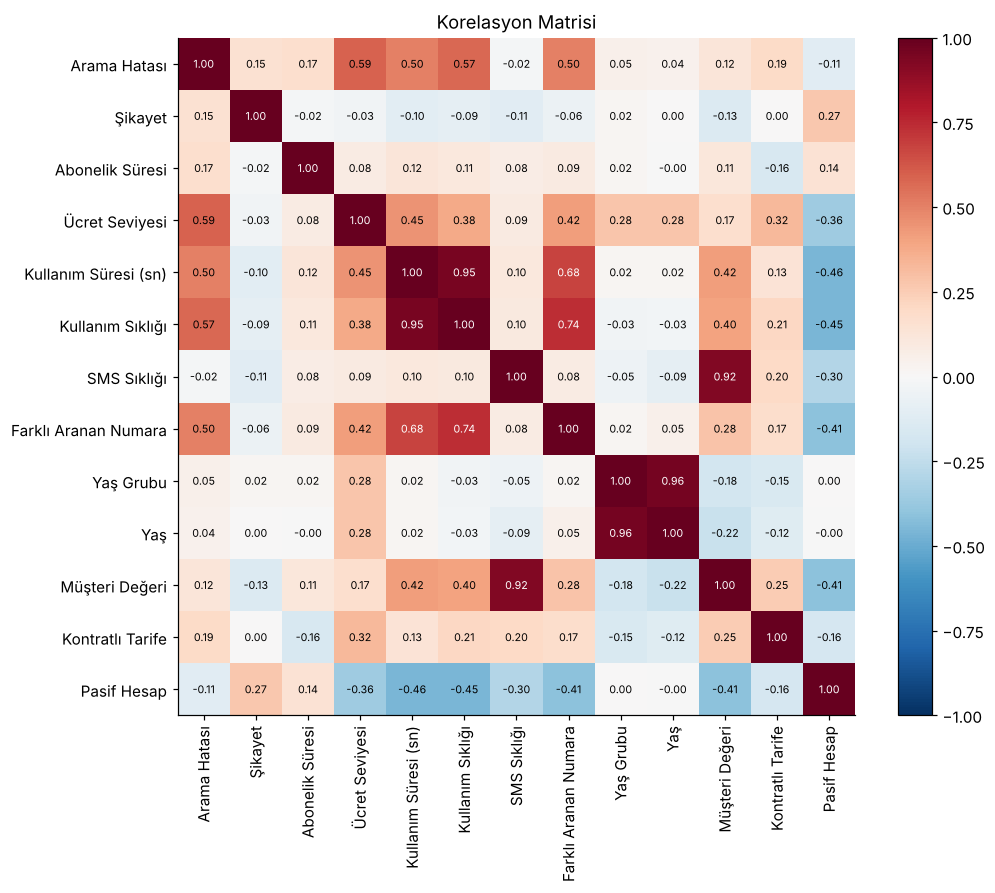

,Özellik,VIF
10,Müşteri Değeri,55.77
6,SMS Sıklığı,43.49
4,Kullanım Süresi (sn),22.78
5,Kullanım Sıklığı,18.88
9,Yaş,14.85
8,Yaş Grubu,14.17
3,Ücret Seviyesi,3.19
0,Arama Hatası,2.92
7,Farklı Aranan Numara,2.47
12,Pasif Hesap,1.85


In [3]:
X = df.drop(columns=[HEDEF])
y = df[HEDEF]
ozellikler = X.columns.tolist()

fig, ax = plt.subplots(figsize=(10, 8))
kor = X.corr()
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kor))); ax.set_xticklabels(kor.columns, rotation=90)
ax.set_yticks(range(len(kor))); ax.set_yticklabels(kor.columns)
for i in range(len(kor)):
    for j in range(len(kor)):
        ax.text(j, i, f"{kor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(kor.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, fraction=0.046)
ax.set_title("Korelasyon Matrisi")
kaydet(fig, "korelasyon_matrisi"); plt.show()

Xs = StandardScaler().fit_transform(X)
vif = pd.DataFrame({"Özellik": ozellikler,
                    "VIF": [variance_inflation_factor(Xs, i) for i in range(Xs.shape[1])]})
vif.sort_values("VIF", ascending=False).round(2)

Yaş / Yaş Grubu, Kullanım Süresi / Kullanım Sıklığı ve SMS Sıklığı / Müşteri Değeri arasında güçlü korelasyon var. VIF değerlerinin 10'un üzerinde olması çoklu bağlantıya işaret ediyor. Bu, PCA'yı denemek için bir gerekçe. VIF tablosu yalnızca betimsel amaçla tüm veri üzerinde hesaplandı. Modellemede kullanılan tüm dönüşümler aşağıda yalnızca eğitim verisiyle öğreniliyor.

## 3. Eğitim / test ayrımı

Veri **önce** ayrılıyor, ölçekleme ve PCA sonra yalnızca eğitim verisi üzerinde öğreniliyor. Bunu sağlamak için tüm ön işleme adımları bir `Pipeline` içine alındı. Böylece çapraz doğrulamanın her katında da test katı ön işlemeye sızmıyor (data leakage önleniyor).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Eğitim: {X_train.shape[0]} | Test: {X_test.shape[0]}")

Eğitim: 2520 | Test: 630


## 4. PCA

%95 varyans için gereken bileşen sayısı: 9 (açıklanan: %97.4)


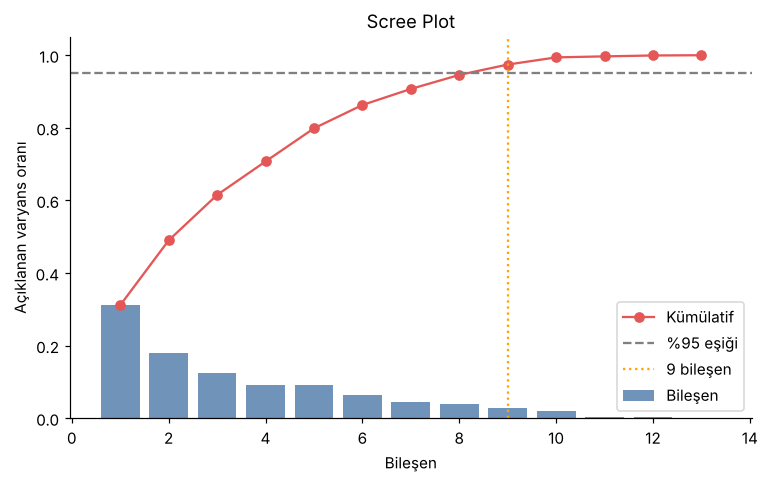

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
Kullanım Sıklığı,0.44,0.05,-0.19,0.05,-0.16,0.18,0.29,0.02,-0.26
Kullanım Süresi (sn),0.43,0.07,-0.14,0.09,-0.18,0.18,0.20,0.01,-0.45
Farklı Aranan Numara,0.39,0.09,-0.16,0.02,-0.12,0.13,0.17,-0.13,0.83
Arama Hatası,0.32,0.19,-0.31,0.03,0.27,-0.11,-0.24,0.48,0.07
Ücret Seviyesi,0.32,0.25,0.04,-0.17,0.22,-0.38,-0.49,0.06,-0.08
Müşteri Değeri,0.31,-0.36,0.36,0.17,0.19,0.15,0.04,0.13,-0.05
SMS Sıklığı,0.19,-0.33,0.52,0.17,0.28,0.11,-0.04,0.18,0.12
Kontratlı Tarife,0.17,-0.14,0.03,-0.53,0.37,-0.42,0.50,-0.28,-0.05
Abonelik Süresi,0.06,0.03,-0.10,0.75,0.17,-0.42,0.03,-0.45,-0.03
Yaş,0.00,0.56,0.38,0.01,0.02,0.06,0.18,-0.03,0.02


In [5]:
pca_kesif = Pipeline([("olcek", StandardScaler()), ("pca", PCA())]).fit(X_train)
oran = pca_kesif.named_steps["pca"].explained_variance_ratio_
kumulatif = np.cumsum(oran)
k95 = int(np.argmax(kumulatif >= 0.95) + 1)
print(f"%95 varyans için gereken bileşen sayısı: {k95} (açıklanan: %{kumulatif[k95-1]*100:.1f})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, len(oran) + 1), oran, color="#4C78A8", alpha=0.8, label="Bileşen")
ax.plot(range(1, len(oran) + 1), kumulatif, "o-", color="#E45756", label="Kümülatif")
ax.axhline(0.95, ls="--", color="gray", label="%95 eşiği")
ax.axvline(k95, ls=":", color="orange", label=f"{k95} bileşen")
ax.set_xlabel("Bileşen"); ax.set_ylabel("Açıklanan varyans oranı")
ax.set_title("Scree Plot"); ax.legend()
kaydet(fig, "scree_plot"); plt.show()

yuklemeler = pd.DataFrame(pca_kesif.named_steps["pca"].components_[:k95].T,
                          index=ozellikler, columns=[f"PC{i+1}" for i in range(k95)]).round(2)
yuklemeler.sort_values("PC1", ascending=False)

İlk bileşen ağırlıklı olarak kullanım yoğunluğunu (kullanım süresi, sıklığı, aranan numara sayısı), ikinci bileşen yaş ile ilgili değişkenleri temsil ediyor. Modellerde bileşen sayısı `PCA(n_components=0.95)` ile her eğitim katında yeniden belirleniyor.

## 5. Modeller

Her model iki şekilde kuruldu: **ham veri** (ölçekleme + model) ve **PCA** (ölçekleme + PCA + model). Hiperparametreler, aynı çapraz doğrulama düzeni ve aynı başarı ölçütüyle (F1) `RandomizedSearchCV` ile arandı. Dengesiz sınıflar için mümkün olan modellerde `class_weight="balanced"` kullanıldı.

In [6]:
def pipeline_kur(model, pca=False):
    adimlar = [("olcek", StandardScaler())]
    if pca:
        adimlar.append(("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)))
    adimlar.append(("model", model))
    return Pipeline(adimlar)

modeller = {
    "Lojistik Regresyon": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"model__C": loguniform(1e-3, 1e2)}, 15),
    "Karar Ağacı": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": randint(3, 25), "model__min_samples_leaf": randint(1, 20),
         "model__ccp_alpha": loguniform(1e-5, 1e-2)}, 30),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": randint(100, 300), "model__max_depth": [5, 10, 15, 20, None],
         "model__min_samples_split": randint(2, 15), "model__min_samples_leaf": randint(1, 8),
         "model__max_features": ["sqrt", "log2", 0.5]}, 15),
    "SVM": (
        SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE),
        {"model__C": loguniform(1e-1, 5e1), "model__kernel": ["rbf", "linear"],
         "model__gamma": ["scale", "auto"]}, 10),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": randint(80, 300), "model__learning_rate": uniform(0.01, 0.19),
         "model__max_depth": randint(2, 6), "model__subsample": uniform(0.7, 0.3)}, 15),
}

def degerlendir(ad, model, sure):
    # .score() yerine tahminlerden açıkça hesaplanan metrikler
    tahmin_tr = model.predict(X_train)
    tahmin = model.predict(X_test)
    olasilik = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, tahmin).ravel()
    return {
        "Model": ad,
        "Train Accuracy": accuracy_score(y_train, tahmin_tr),
        "Test Accuracy": accuracy_score(y_test, tahmin),
        "Train F1": f1_score(y_train, tahmin_tr),
        "Test F1": f1_score(y_test, tahmin),
        "F1 Farkı (Train-Test)": f1_score(y_train, tahmin_tr) - f1_score(y_test, tahmin),
        "Precision": precision_score(y_test, tahmin),
        "Recall": recall_score(y_test, tahmin),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(y_test, olasilik),
        "PR-AUC": average_precision_score(y_test, olasilik),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Arama Süresi (s)": sure,
    }

sonuclar, egitilmis = [], {}
for ad, (tahminci, uzay, n_iter) in modeller.items():
    for pca in (False, True):
        etiket = f"{ad} — {'PCA' if pca else 'Ham'}"
        arama = RandomizedSearchCV(pipeline_kur(tahminci, pca), uzay, n_iter=n_iter,
                                   scoring="f1", cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
        t0 = time.time(); arama.fit(X_train, y_train); sure = time.time() - t0
        egitilmis[etiket] = arama
        sonuclar.append(degerlendir(etiket, arama.best_estimator_, sure))
        print(f"{etiket:<32} CV F1={arama.best_score_:.3f} | Test F1={sonuclar[-1]['Test F1']:.3f} | {sure:.1f}s")

tablo = pd.DataFrame(sonuclar).sort_values("Test F1", ascending=False).reset_index(drop=True)
tablo.to_csv(RES_DIR / "model_karsilastirma.csv", index=False, encoding="utf-8-sig")
tablo.round(3)

Lojistik Regresyon — Ham         CV F1=0.656 | Test F1=0.632 | 2.0s


Lojistik Regresyon — PCA         CV F1=0.656 | Test F1=0.637 | 0.7s


Karar Ağacı — Ham                CV F1=0.806 | Test F1=0.804 | 1.4s


Karar Ağacı — PCA                CV F1=0.747 | Test F1=0.775 | 1.8s


Random Forest — Ham              CV F1=0.873 | Test F1=0.887 | 20.4s


...

SVM — Ham                        CV F1=0.791 | Test F1=0.798 | 9.4s


SVM — PCA                        CV F1=0.743 | Test F1=0.758 | 9.7s


Gradient Boosting — Ham          CV F1=0.856 | Test F1=0.872 | 31.0s


Gradient Boosting — PCA          CV F1=0.803 | Test F1=0.800 | 42.4s


,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,F1 Farkı (Train-Test),Precision,Recall,Specificity,ROC-AUC,PR-AUC,TP,FP,FN,TN,Arama Süresi (s)
0,Random Forest — Ham,0.982,0.962,0.946,0.887,0.059,0.832,0.949,0.964,0.987,0.929,94,19,5,512,20.351
1,Gradient Boosting — Ham,0.993,0.960,0.977,0.872,0.105,0.885,0.859,0.979,0.981,0.880,85,11,14,520,31.037
2,Random Forest — PCA,0.976,0.944,0.928,0.840,0.088,0.767,0.929,0.947,0.976,0.899,92,28,7,503,27.262
3,Karar Ağacı — Ham,0.991,0.938,0.972,0.804,0.168,0.800,0.808,0.962,0.888,0.706,80,20,19,511,1.356
4,Gradient Boosting — PCA,0.993,0.941,0.977,0.800,0.177,0.860,0.747,0.977,0.972,0.871,74,12,25,519,42.413
5,SVM — Ham,0.930,0.922,0.815,0.798,0.016,0.674,0.980,0.911,0.981,0.926,97,47,2,484,9.373
6,Karar Ağacı — PCA,0.991,0.927,0.972,0.775,0.197,0.752,0.798,0.951,0.877,0.655,79,26,20,505,1.793
7,SVM — PCA,0.911,0.902,0.774,0.758,0.017,0.618,0.980,0.887,0.972,0.859,97,60,2,471,9.686
8,Lojistik Regresyon — PCA,0.852,0.844,0.657,0.637,0.020,0.503,0.869,0.840,0.914,0.738,86,85,13,446,0.682
9,Lojistik Regresyon — Ham,0.851,0.841,0.654,0.632,0.022,0.497,0.869,0.836,0.915,0.739,86,87,13,444,2.029


## 6. Sonuçların karşılaştırılması

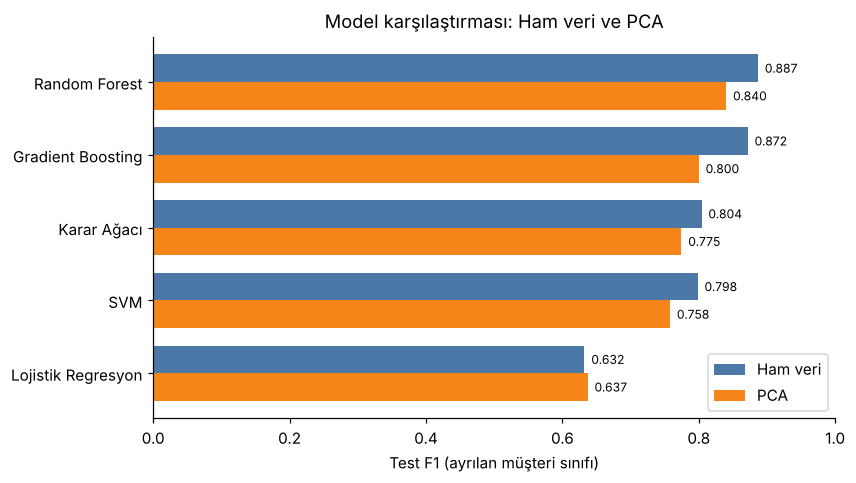

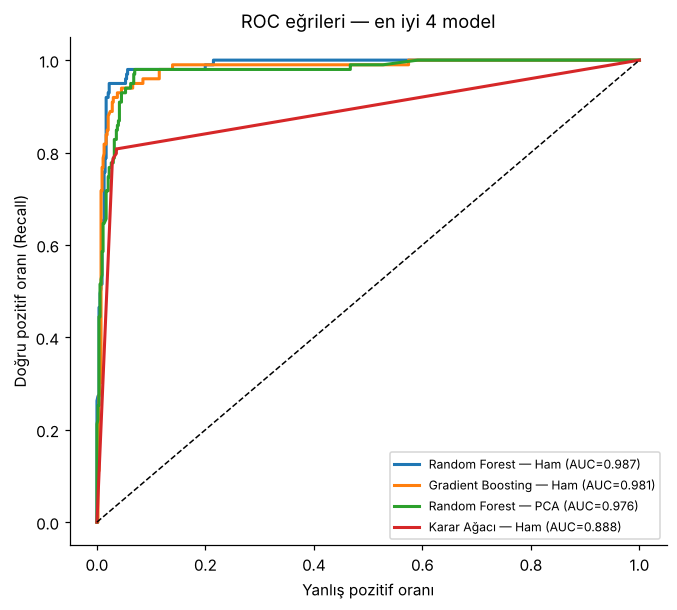

In [7]:
parca = tablo["Model"].str.split(" — ", expand=True)
ham = tablo[parca[1] == "Ham"].set_index(parca.loc[parca[1] == "Ham", 0])
pcal = tablo[parca[1] == "PCA"].set_index(parca.loc[parca[1] == "PCA", 0])
sira = ham["Test F1"].sort_values().index

fig, ax = plt.subplots(figsize=(8, 4.5))
yy = np.arange(len(sira)); h = 0.38
ax.barh(yy + h/2, ham.loc[sira, "Test F1"], h, label="Ham veri", color="#4C78A8")
ax.barh(yy - h/2, pcal.loc[sira, "Test F1"], h, label="PCA", color="#F58518")
ax.set_yticks(yy); ax.set_yticklabels(sira)
ax.set_xlabel("Test F1 (ayrılan müşteri sınıfı)"); ax.set_xlim(0, 1)
ax.set_title("Model karşılaştırması: Ham veri ve PCA"); ax.legend(loc="lower right")
for i, m in enumerate(sira):
    ax.text(ham.loc[m, "Test F1"] + 0.01, i + h/2, f"{ham.loc[m, 'Test F1']:.3f}", va="center", fontsize=8)
    ax.text(pcal.loc[m, "Test F1"] + 0.01, i - h/2, f"{pcal.loc[m, 'Test F1']:.3f}", va="center", fontsize=8)
kaydet(fig, "model_karsilastirma"); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for etiket in tablo["Model"].head(4):
    olas = egitilmis[etiket].best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, olas)
    ax.plot(fpr, tpr, lw=2, label=f"{etiket} (AUC={roc_auc_score(y_test, olas):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("Yanlış pozitif oranı"); ax.set_ylabel("Doğru pozitif oranı (Recall)")
ax.set_title("ROC eğrileri — en iyi 4 model"); ax.legend(loc="lower right", fontsize=8)
kaydet(fig, "roc_egrileri"); plt.show()

## 7. En iyi model: hata analizi ve aşırı öğrenme kontrolü

En iyi model: Random Forest — Ham
Parametreler: {'max_depth': 15, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 149}
Train Accuracy    0.9821
Test Accuracy     0.9619
Train F1          0.9462
Test F1           0.8868
Precision         0.8319
Recall            0.9495
ROC-AUC           0.9871


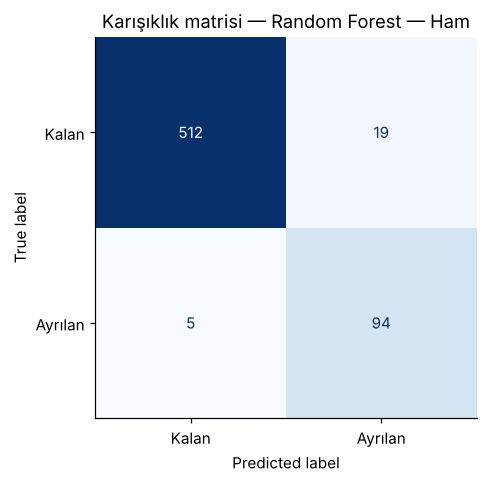

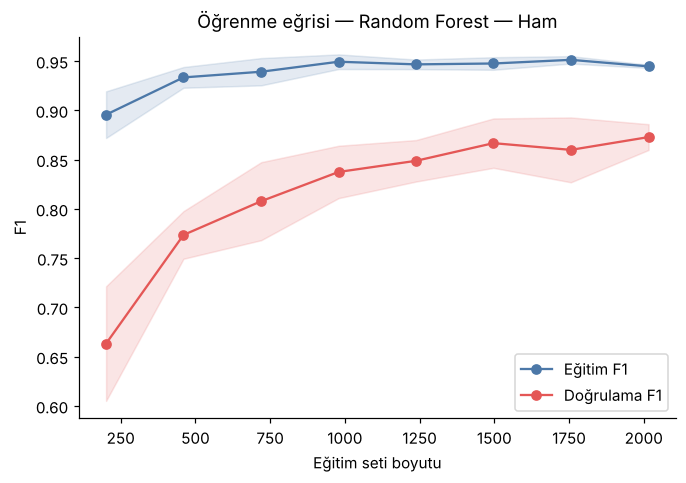

In [8]:
en_iyi_ad = tablo.loc[0, "Model"]
en_iyi = egitilmis[en_iyi_ad].best_estimator_
print("En iyi model:", en_iyi_ad)
print("Parametreler:", {k.replace("model__", ""): v for k, v in egitilmis[en_iyi_ad].best_params_.items()})
print(tablo.loc[0, ["Train Accuracy", "Test Accuracy", "Train F1", "Test F1",
                    "Precision", "Recall", "ROC-AUC"]].round(4).to_string())

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, en_iyi.predict(X_test)),
                       display_labels=["Kalan", "Ayrılan"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Karışıklık matrisi — {en_iyi_ad}")
kaydet(fig, "karisiklik_matrisi"); plt.show()

boyutlar, tr, te = learning_curve(en_iyi, X_train, y_train, cv=cv, scoring="f1",
                                  train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for skor, renk, ad in [(tr, "#4C78A8", "Eğitim F1"), (te, "#E45756", "Doğrulama F1")]:
    ax.plot(boyutlar, skor.mean(1), "o-", color=renk, label=ad)
    ax.fill_between(boyutlar, skor.mean(1) - skor.std(1), skor.mean(1) + skor.std(1), color=renk, alpha=0.15)
ax.set_xlabel("Eğitim seti boyutu"); ax.set_ylabel("F1")
ax.set_title(f"Öğrenme eğrisi — {en_iyi_ad}"); ax.legend()
kaydet(fig, "ogrenme_egrisi"); plt.show()

Eğitim ve doğrulama eğrileri arasındaki fark, veri miktarı arttıkça daralıyorsa model daha fazla veriden fayda görüyor demektir. Ağaç tabanlı topluluk modellerinin eğitim skorunun 1'e yakın olması beklenen bir durumdur. Asıl ölçüt, test/doğrulama performansının yüksek ve kararlı olmasıdır.

## 8. Hangi değişkenler ayrılmayı belirliyor?

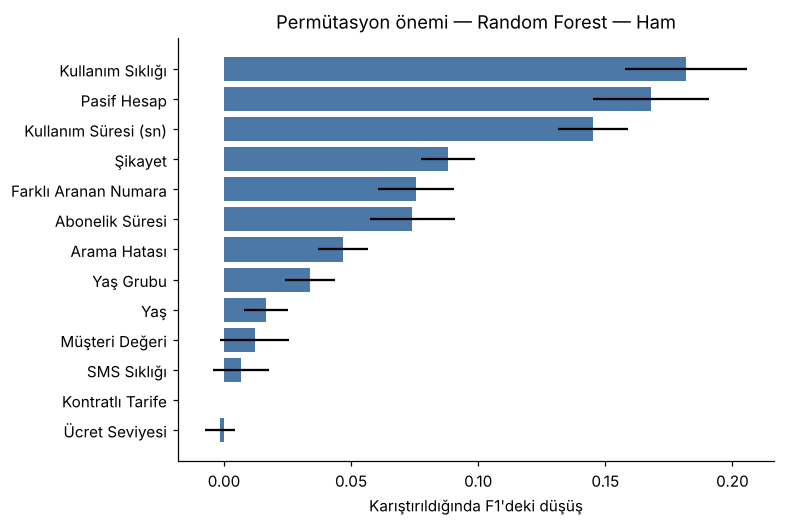

,Özellik,Önem,Std
5,Kullanım Sıklığı,0.182,0.024
12,Pasif Hesap,0.168,0.023
4,Kullanım Süresi (sn),0.145,0.014
1,Şikayet,0.088,0.011
7,Farklı Aranan Numara,0.076,0.015
2,Abonelik Süresi,0.074,0.017
0,Arama Hatası,0.047,0.010
8,Yaş Grubu,0.034,0.010
9,Yaş,0.016,0.009
10,Müşteri Değeri,0.012,0.014


In [9]:
onem = permutation_importance(en_iyi, X_test, y_test, scoring="f1", n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=-1)
onem_df = (pd.DataFrame({"Özellik": ozellikler, "Önem": onem.importances_mean, "Std": onem.importances_std})
           .sort_values("Önem"))
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(onem_df["Özellik"], onem_df["Önem"], xerr=onem_df["Std"], color="#4C78A8")
ax.set_xlabel("Karıştırıldığında F1'deki düşüş")
ax.set_title(f"Permütasyon önemi — {en_iyi_ad}")
kaydet(fig, "degisken_onemi"); plt.show()
onem_df.sort_values("Önem", ascending=False).round(3)

Permütasyon önemi, bir değişkenin değerleri karıştırıldığında modelin test performansının ne kadar düştüğünü ölçer. Hem ham hem PCA modelleri için aynı şekilde hesaplanabilir ve Gini öneminin sürekli değişkenleri kayırma eğiliminden etkilenmez.

Yorumlanabilirlik için budanmış tek bir karar ağacının ilk seviyeleri de aşağıda verilmiştir:

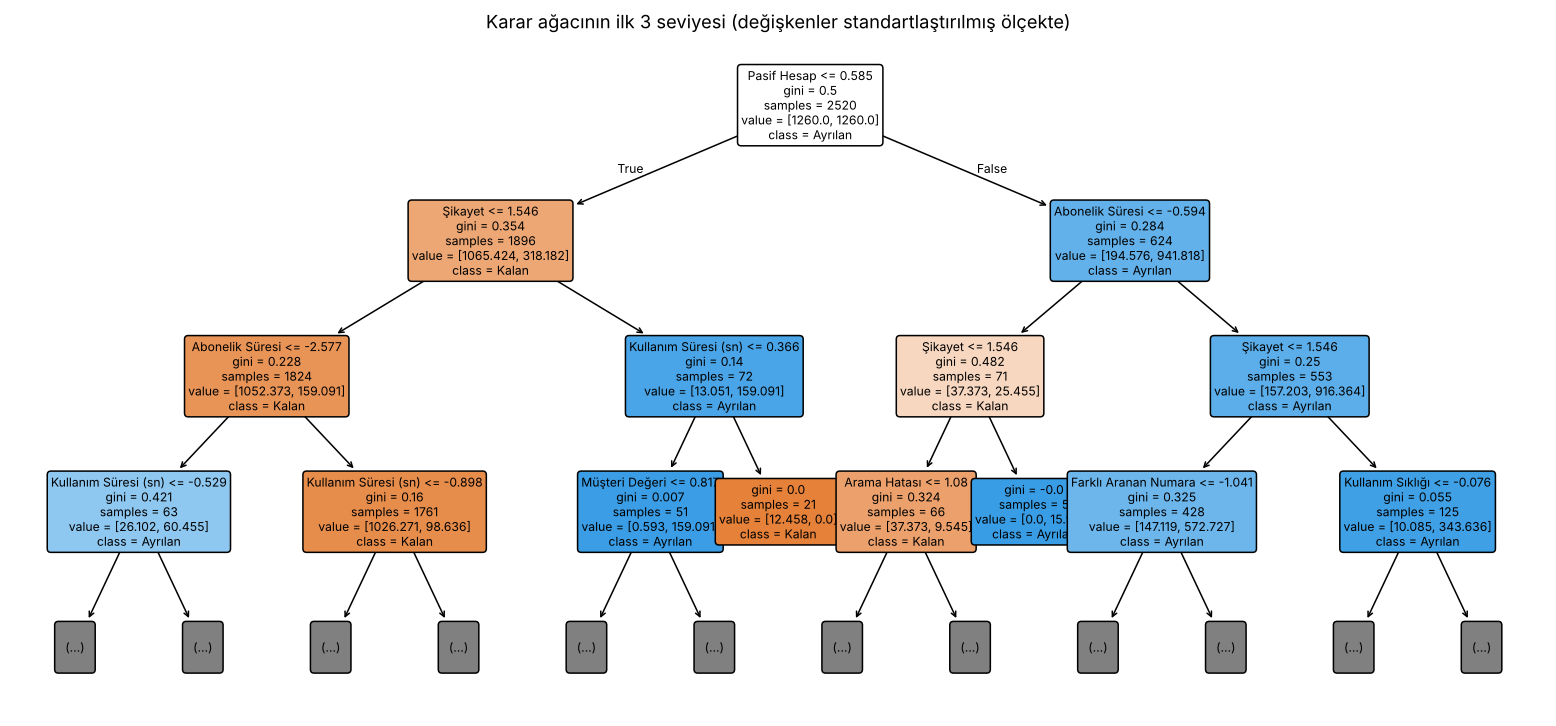

In [10]:
agac = egitilmis["Karar Ağacı — Ham"].best_estimator_
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(agac.named_steps["model"], max_depth=3, feature_names=ozellikler,
          class_names=["Kalan", "Ayrılan"], filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Karar ağacının ilk 3 seviyesi (değişkenler standartlaştırılmış ölçekte)")
kaydet(fig, "karar_agaci"); plt.show()

## 9. Grid Search ile Randomized Search karşılaştırması

En iyi parametre aramasının maliyetini görmek için Random Forest ham veri modelinde iki yöntem aynı CV düzeniyle karşılaştırıldı.

In [11]:
rf_pipe = pipeline_kur(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
grid = {"model__n_estimators": [100, 200], "model__max_depth": [10, 20, None],
        "model__min_samples_split": [2, 5, 10], "model__max_features": ["sqrt", "log2"]}
dagilim = {"model__n_estimators": randint(100, 300), "model__max_depth": [5, 10, 15, 20, 30, None],
           "model__min_samples_split": randint(2, 15), "model__min_samples_leaf": randint(1, 8),
           "model__max_features": ["sqrt", "log2", 0.3, 0.5], "model__bootstrap": [True, False]}

arama_sonuc = []
for ad, arama in [("Grid Search (36 kombinasyon)", GridSearchCV(rf_pipe, grid, scoring="f1", cv=cv, n_jobs=-1)),
                  ("Randomized Search (20 deneme)", RandomizedSearchCV(rf_pipe, dagilim, n_iter=20, scoring="f1",
                                                                       cv=cv, n_jobs=-1, random_state=RANDOM_STATE))]:
    t0 = time.time(); arama.fit(X_train, y_train); sure = time.time() - t0
    tahmin = arama.predict(X_test)
    arama_sonuc.append({"Yöntem": ad, "CV F1": arama.best_score_, "Test F1": f1_score(y_test, tahmin),
                        "Test Accuracy": accuracy_score(y_test, tahmin), "Süre (s)": sure})
pd.DataFrame(arama_sonuc).round(3)

,Yöntem,CV F1,Test F1,Test Accuracy,Süre (s)
0,Grid Search (36 kombinasyon),0.884,0.904,0.968,42.611
1,Randomized Search (20 deneme),0.870,0.904,0.968,35.683


## 10. İş açısından yorum: kampanya kime yapılmalı?

Şirket her müşteriyi aramak yerine, modelin ayrılma olasılığına göre sıraladığı en riskli müşterilerle iletişime geçebilir. Kazanç eğrisi, en riskli %X müşteriye ulaşıldığında gerçekte ayrılacak müşterilerin yüzde kaçının yakalandığını gösterir.

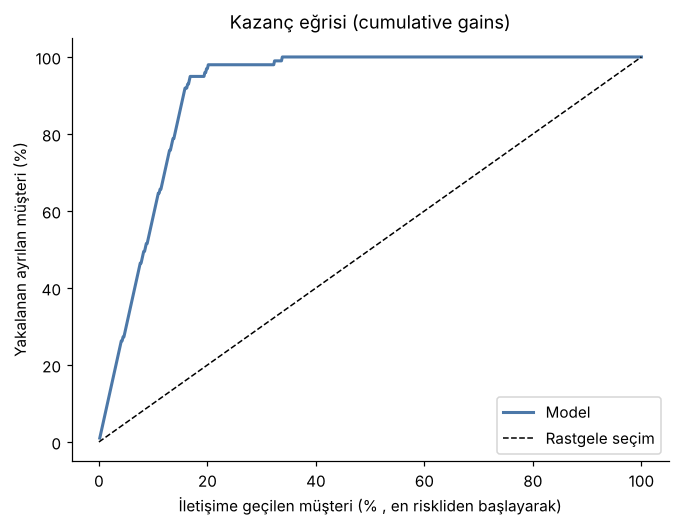

,Ulaşılan müşteri,Yakalanan ayrılan müşteri
0,%10,%59
1,%20,%97
2,%30,%98


In [12]:
olas = en_iyi.predict_proba(X_test)[:, 1]
sirali = y_test.values[np.argsort(-olas)]
oranlar = np.arange(1, len(sirali) + 1) / len(sirali)
yakalanan = np.cumsum(sirali) / sirali.sum()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(oranlar * 100, yakalanan * 100, color="#4C78A8", lw=2, label="Model")
ax.plot([0, 100], [0, 100], "k--", lw=1, label="Rastgele seçim")
ax.set_xlabel("İletişime geçilen müşteri (% , en riskliden başlayarak)")
ax.set_ylabel("Yakalanan ayrılan müşteri (%)")
ax.set_title("Kazanç eğrisi (cumulative gains)"); ax.legend(loc="lower right")
kaydet(fig, "kazanc_egrisi"); plt.show()

ozet_kazanc = pd.DataFrame({
    "Ulaşılan müşteri": ["%10", "%20", "%30"],
    "Yakalanan ayrılan müşteri": [f"%{yakalanan[int(len(sirali)*p)-1]*100:.0f}" for p in (0.1, 0.2, 0.3)],
})
ozet_kazanc.to_csv(RES_DIR / "kazanc_ozeti.csv", index=False, encoding="utf-8-sig")
ozet_kazanc

## 11. Sonuç

- Ham veri üzerinde kurulan ağaç tabanlı topluluk modelleri (Random Forest, Gradient Boosting), bu veri setinde en yüksek F1 ve ROC-AUC değerlerine ulaştı. Sayısal sonuçlar `results/model_karsilastirma.csv` dosyasındadır.
- PCA çoklu bağlantıyı gideriyor ancak bu veri setinde tahmin başarısını artırmadı. Ağaç tabanlı modeller çoklu bağlantıdan zaten etkilenmez ve PCA, bilgiyi yorumlanması zor bileşenlere dağıtır.
- Dengesiz hedef değişken nedeniyle doğruluk tek başına yeterli değil. F1, recall ve PR-AUC birlikte değerlendirilmeli.
- Şikayet, hesap durumu (pasif/aktif) ve kullanım yoğunluğu ayrılmayı en çok belirleyen değişkenler arasında.

**Sınırlılıklar:** Veri tek bir şirketten ve 3.150 müşteriden oluşuyor. Sonuçlar tek bir eğitim/test ayrımına dayanıyor. Gerçek bir uygulamada karar eşiği, kampanya maliyeti ile kaybedilen müşterinin değeri karşılaştırılarak seçilmelidir.